In [42]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings("ignore")

In [43]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from collections import Counter

In [44]:
x,y=make_classification(n_samples=1000,n_features=2,n_clusters_per_class=1,n_redundant=0,weights=[0.99],random_state=10)

In [45]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42) 

In [46]:
Counter(y)

Counter({np.int64(0): 985, np.int64(1): 15})

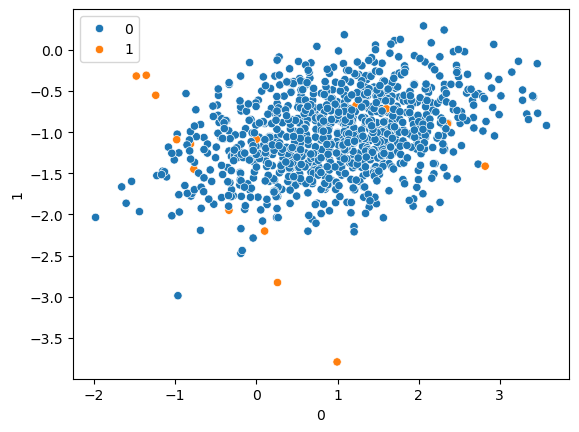

In [47]:
df = pd.DataFrame(x)

sns.scatterplot(x=df[0], y=df[1], hue=y)

plt.show()

In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
from sklearn.utils import class_weight
model=LogisticRegression()
penalty=['l1', 'l2', 'elasticnet']
c_value=[100,10,0.1,0.001,1.0]
sol=['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
class_weights=[{0:w,y:1} for w in [1,10,50,100] for y in [1,10,50,100]]

In [50]:
para=dict(penalty=penalty,C=c_value,solver=sol,class_weight=class_weights)

In [51]:
para

{'penalty': ['l1', 'l2', 'elasticnet'],
 'C': [100, 10, 0.1, 0.001, 1.0],
 'solver': ['lbfgs',
  'liblinear',
  'newton-cg',
  'newton-cholesky',
  'sag',
  'saga'],
 'class_weight': [{0: 1, 1: 1},
  {0: 1, 10: 1},
  {0: 1, 50: 1},
  {0: 1, 100: 1},
  {0: 10, 1: 1},
  {0: 10, 10: 1},
  {0: 10, 50: 1},
  {0: 10, 100: 1},
  {0: 50, 1: 1},
  {0: 50, 10: 1},
  {0: 50, 50: 1},
  {0: 50, 100: 1},
  {0: 100, 1: 1},
  {0: 100, 10: 1},
  {0: 100, 50: 1},
  {0: 100, 100: 1}]}

In [52]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
cv=StratifiedKFold()
hyp=GridSearchCV(estimator=model,param_grid=para,cv=cv,scoring="accuracy")

In [54]:
hyp.fit(X_train,y_train)

,estimator,LogisticRegression()
,param_grid,"{'C': [100, 10, ...], 'class_weight': [{0: 1, 1: 1}, {0: 1, 10: 1}, ...], 'penalty': ['l1', 'l2', ...], 'solver': ['lbfgs', 'liblinear', ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,StratifiedKFo...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [55]:
y_pred=hyp.predict(X_test)

In [57]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [58]:
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.9848484848484849
[[325   0]
 [  5   0]]
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       325
           1       0.00      0.00      0.00         5

    accuracy                           0.98       330
   macro avg       0.49      0.50      0.50       330
weighted avg       0.97      0.98      0.98       330

